# Experimento 5 · Análisis de sentimiento de las reseñas con JEV (LLM)

> **Requiere la API key de JEV.** No necesita GPU: el modelo corre del lado del proveedor.

**Idea.** En lugar de un clasificador afinado (BETO), se le pide a un modelo de lenguaje grande que lea cada reseña y diga si el autor opinó positiva, neutral o negativamente de la película, más un puntaje continuo en [-1, 1]. Un LLM entiende sarcasmo, modismos mexicanos y emojis sin entrenamiento adicional (*zero-shot*), a cambio de costo por uso y menor reproducibilidad.

**Diseño de la consulta.**
* Se envían **lotes de 20 reseñas** por petición (menos peticiones y menos costo que una por una), numeradas; el modelo responde un arreglo JSON con la misma numeración.
* **Nunca** se le muestran las estrellas: solo el texto. Las estrellas se usan después para evaluar.
* Temperatura 0 para que la respuesta sea lo más estable posible.
* Todo lo recibido se guarda en un caché (`datos/limpios/sentimiento/jev_cache.jsonl`): si se interrumpe, al volver a correr retoma donde iba y no paga dos veces.

**Por seguridad, el notebook primero corre un piloto** de 100 reseñas, muestra su calidad y el consumo de tokens, y solo procesa todo si pones `EJECUTAR_TODO = True`.

**Entrada:** `datos/limpios/resenas_sentimiento.parquet` (columna `texto_llm`: limpia, conserva emojis).
**Salida:** `datos/limpios/sentimiento/sentimiento_jev.parquet`, con el mismo formato que BETO. Con ese archivo, los notebooks 01–03 corren la **variante C**.

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [2]:
import os; os.environ['TT_RAIZ'] = '/content/drive/MyDrive/TT_Recomendador_Cine_Mexicano'

import os, sys, warnings
from pathlib import Path
RAIZ = Path(os.environ.get('TT_RAIZ', Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
os.environ['TT_RAIZ'] = str(RAIZ)
sys.path.insert(0, str(RAIZ / 'src'))
warnings.filterwarnings('ignore', category=FutureWarning)
print('Raíz del proyecto:', RAIZ)

Raíz del proyecto: /content/drive/MyDrive/TT_Recomendador_Cine_Mexicano


In [3]:
import os
from getpass import getpass

JEV_API_KEY = os.environ.get('JEV_API_KEY') or getpass('API key de TypeSafe: ')
JEV_URL = os.environ.get('JEV_URL', 'https://api.defapi.org/api/v1/decisions')   # endpoint oficial (docs.typesafe.ai)
JEV_MODELO = os.environ.get('JEV_MODELO', 'typesafe/jev-1.14.0')   # alias; para fijar versión usa p. ej. 'jev-1.13.0'

# --- Parámetros ---------------------------------------------------------------------
HILOS = 8                      # peticiones en paralelo; bájalo si aparecen errores 429
MAX_CARACTERES = 1500          # se recorta cada reseña (el p95 es ~485)
PILOTO = 1000
EJECUTAR_TODO = True          # ← ponlo en True después de revisar el piloto
MAX_RESENAS = None             # tope opcional por presupuesto (None = las ~151 mil)
PRECIO_ENTRADA_USD_1M = 0.05   # USD por millón de tokens de entrada (verifica en tu consola)
PRECIO_SALIDA_USD_1M = 0.0     # la salida hoy no se cobra (docs.typesafe.ai/api/system-one)
SEMILLA = 42

API key de TypeSafe: ··········


In [4]:
sys.path.append('/content/drive/MyDrive/TT_Recomendador_Cine_Mexicano/TT_Recomendador_Cine_Mexicano/src')

In [5]:
import json, re, time, threading
from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
import requests
from tqdm.auto import tqdm

from recomendador import rutas, sentimiento as S

SALIDA = rutas.carpeta_resultados('exp5')
rutas.SENTIMIENTO.mkdir(parents=True, exist_ok=True)
CACHE = rutas.SENTIMIENTO / 'jev_cache.jsonl'
res = pd.read_parquet(rutas.LIMPIOS / 'resenas_sentimiento.parquet').sort_values('id').reset_index(drop=True)
print(f'{len(res):,} reseñas en español  ·  por grupo: {res.grupo.value_counts().to_dict()}')

151,516 reseñas en español  ·  por grupo: {'g5': 119872, 'g34': 31644}


## 1. La única función que depende del proveedor

Usa el formato *chat completions* compatible con OpenAI, que es el que ofrecen la mayoría de los servicios de LLM. **Si JEV usa otro formato, solo hay que cambiar esta celda**: recibe la lista de mensajes y devuelve el texto de la respuesta y el uso de tokens.

In [6]:
_local = threading.local()   # una sesión HTTP por hilo
REINTENTABLES = (429, 500, 502, 503, 504, 529)


class JevError(RuntimeError):
    """Error no recuperable (credenciales, petición inválida…)."""


def _sesion():
    if not hasattr(_local, 'sesion'):
        _local.sesion = requests.Session()
    return _local.sesion


def llamar_jev(state, preguntas, intentos=6):
    """Envía `state` y `preguntas` a JEV; devuelve (answers, usage)."""
    for intento in range(intentos):
        try:
            r = _sesion().post(
                JEV_URL,
                headers={'Authorization': f'Bearer {JEV_API_KEY}', 'Content-Type': 'application/json'},
                json={'model': JEV_MODELO, 'state': state, 'questions': preguntas},
                timeout=120,
            )
            if r.status_code in REINTENTABLES:
                raise requests.HTTPError(f'HTTP {r.status_code}', response=r)
            if not r.ok:
                raise JevError(f'HTTP {r.status_code}: {r.text[:300]}')
            datos = r.json()
            return datos['answers'], datos.get('usage', {})
        except (requests.ConnectionError, requests.Timeout, requests.HTTPError) as e:
            if intento == intentos - 1:
                raise
            espera = min(60, 2 ** intento) + np.random.rand()
            print(f'  reintento {intento + 1} en {espera:.0f} s ({e})')
            time.sleep(espera)

## 2. Instrucciones (prompt)

Se pide la opinión del autor **sobre la película**, no sobre los personajes o la trama: "el villano es repugnante" puede venir de alguien a quien le encantó la película. Los ejemplos fijan el formato y calibran la escala.

In [7]:
PREGUNTA = {
    'sentimiento': {
        'type': 'choice',
        'instructions': ('Reseña de cine escrita en español, casi siempre por usuarios de México. '
                         '¿Cuál es la opinión del AUTOR sobre la PELÍCULA (no sobre los personajes, la trama '
                         'o los actores por separado)? Ten en cuenta el sarcasmo, los modismos mexicanos '
                         '("está chida", "qué hueva", "un churro") y los emojis.'),
        'criteria': {
            'negativo': 'No le gustó la película, la critica o no la recomienda.',
            'neutral': 'Opinión mixta o indiferente, o solo describe sin valorar.',
            'positivo': 'Le gustó la película o la recomienda.',
        },
    }
}


def armar_state(texto):
    return str(texto)[:MAX_CARACTERES]


def interpretar(answers):
    """De la respuesta de JEV a (etiqueta, s, p_neg, p_neu, p_pos). Devuelve None si no es utilizable."""
    r = answers.get('sentimiento')
    if not r or r.get('type') != 'choice':
        return None
    p = r.get('probabilities', {})
    try:
        p_neg, p_neu, p_pos = (float(p[k]) for k in ('negativo', 'neutral', 'positivo'))
    except (KeyError, TypeError, ValueError):
        return None
    etq = r.get('choice')
    if etq not in ('negativo', 'neutral', 'positivo'):
        return None
    return etq, p_pos - p_neg, p_neg, p_neu, p_pos


# Prueba de conexión con una reseña de ejemplo (falla rápido si algo está mal)
ans, uso = llamar_jev('Qué chulada de película, lloré todo el final 😭', PREGUNTA, intentos=1)
print('Respuesta:', ans, '· uso:', uso)
print('Interpretado:', interpretar(ans))

Respuesta: {'sentimiento': {'type': 'choice', 'choice': 'positivo', 'probabilities': {'negativo': 0.03, 'neutral': 0, 'positivo': 0.97}, 'confidence': 0.96}} · uso: {'input_tokens': 446, 'output_tokens': 43, 'cost': 3.7464e-05, 'is_byok': False, 'cost_details': {'upstream_inference_cost': 1.8732e-05, 'upstream_inference_prompt_cost': 1.8732e-05, 'upstream_inference_completions_cost': 0}}
Interpretado: ('positivo', 0.94, 0.03, 0.0, 0.97)


## 3. Procesamiento por lotes con caché

In [8]:
import hashlib

# Huella de lo que determina el resultado: modelo + pregunta.
# Si cambias cualquiera, el caché anterior deja de usarse (no se mezclan corridas).
CLAVE = hashlib.sha1(
    f'{JEV_MODELO}|{json.dumps(PREGUNTA, sort_keys=True, ensure_ascii=False)}|{MAX_CARACTERES}'.encode('utf-8')
).hexdigest()[:10]
print('Clave de caché:', CLAVE)

_candado = threading.Lock()
USO = {'input_tokens': 0, 'output_tokens': 0, 'peticiones': 0, 'fallidas': 0, 'resenas': 0}
_errores = {}


def leer_cache():
    """Lee solo las filas de esta CLAVE y salta líneas corruptas (p. ej. una
    escritura interrumpida a medias)."""
    if not CACHE.exists():
        return {}
    hechos = {}
    with open(CACHE, encoding='utf-8') as f:
        for linea in f:
            try:
                d = json.loads(linea)
            except json.JSONDecodeError:
                continue
            if d.get('clave') == CLAVE:
                hechos[d['id']] = d
    return hechos


def procesar_resena(rid, texto):
    try:
        answers, uso = llamar_jev(armar_state(texto), PREGUNTA)
        r = interpretar(answers)
        if r is None:
            raise JevError(f'respuesta inesperada: {str(answers)[:200]}')
    except Exception as e:
        with _candado:
            USO['fallidas'] += 1
            msg = str(e)[:200]
            if msg not in _errores:            # cada tipo de error se muestra una sola vez
                _errores[msg] = 1
                print('  reseña fallida:', msg)
            else:
                _errores[msg] += 1
        return 0
    etq, s, p_neg, p_neu, p_pos = r
    fila = {'id': rid, 'etiqueta': etq, 's': s, 'p_neg': p_neg, 'p_neu': p_neu, 'p_pos': p_pos,
            'modelo': JEV_MODELO, 'clave': CLAVE}
    with _candado:
        with open(CACHE, 'a', encoding='utf-8') as f:
            f.write(json.dumps(fila, ensure_ascii=False) + '\n')
        USO['peticiones'] += 1
        USO['resenas'] += 1
        USO['input_tokens'] += int(uso.get('input_tokens', 0) or 0)
        USO['output_tokens'] += int(uso.get('output_tokens', 0) or 0)
    return 1


def procesar(df: pd.DataFrame, descripcion='reseñas'):
    hechos = leer_cache()
    pendientes = df[~df.id.isin(hechos)]
    print(f'{len(df) - len(pendientes):,} ya en caché · {len(pendientes):,} por procesar')
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=HILOS) as ex:
        futuros = [ex.submit(procesar_resena, rid, t) for rid, t in zip(pendientes.id, pendientes.texto_llm)]
        for _ in tqdm(as_completed(futuros), total=len(futuros), desc=descripcion):
            pass
    return time.time() - t0


def costo(uso):
    if PRECIO_ENTRADA_USD_1M is None or PRECIO_SALIDA_USD_1M is None:
        return None
    return (uso['input_tokens'] / 1e6 * PRECIO_ENTRADA_USD_1M
            + uso['output_tokens'] / 1e6 * PRECIO_SALIDA_USD_1M)

Clave de caché: 9ae7d67156


## 4. Piloto (100 reseñas con estrellas)

In [9]:
piloto = res[res.calificacion.notna()].sample(PILOTO, random_state=SEMILLA)
segundos = procesar(piloto, 'piloto')
cache = pd.DataFrame(leer_cache().values())
assert len(cache), 'JEV no devolvió ninguna respuesta válida: revisa JEV_URL, JEV_MODELO y la API key.'
eval_piloto = piloto.merge(cache, on='id')
print(f'Respondidas: {len(eval_piloto)}/{len(piloto)} · fallidas: {USO["fallidas"]} · {segundos:.0f} s')
print('Tokens:', {k: USO[k] for k in ('input_tokens', 'output_tokens', 'peticiones')})
if USO['resenas']:
    n = USO['resenas']
    por_resena = USO['input_tokens'] / n
    total = len(res) if MAX_RESENAS is None else min(MAX_RESENAS, len(res))
    print(f'≈ {por_resena:.0f} tokens de entrada por reseña → ≈ {por_resena * total / 1e6:.1f} M tokens para {total:,} reseñas')
    c = costo(USO)
    if c is not None:
        print(f'Costo del piloto ≈ USD {c:.3f} → total estimado ≈ USD {c / n * total:,.2f}')
    print(f'Tiempo estimado total con {HILOS} hilos ≈ {segundos / n * total / 3600:.1f} h')
else:
    print('El piloto ya estaba en caché: no hay consumo nuevo que medir.')
resumen_piloto, matriz_piloto = S.evaluar_contra_estrellas(eval_piloto)
display(pd.Series(resumen_piloto).to_frame('piloto'))
display(eval_piloto[['calificacion', 'etiqueta', 's', 'texto_llm']].head(10))

1,000 ya en caché · 0 por procesar


piloto: 0it [00:00, ?it/s]

Respondidas: 1000/1000 · fallidas: 0 · 0 s
Tokens: {'input_tokens': 0, 'output_tokens': 0, 'peticiones': 0}
El piloto ya estaba en caché: no hay consumo nuevo que medir.


,piloto
resenas_evaluadas,1000
exactitud,0.554
f1_macro,0.518545
kappa_cohen,0.291409
f1_negativo,0.518018
f1_neutral,0.362319
f1_positivo,0.675299
spearman_s_vs_estrellas,0.490258
pearson_s_vs_estrellas,0.509181
mae_estrellas,0.97742


,calificacion,etiqueta,s,texto_llm
0,3.5,positivo,0.30,"Entretenido y curiosamente grande, que si te a..."
1,4.5,neutral,-0.40,"- ""No es fácil, es grande tarea cambiar lo que..."
2,4.5,positivo,0.99,"Ver ""Sin Señas Particulares"" es impactante no ..."
3,3.0,positivo,0.45,Sales de ver una película como Chronic y estás...
4,2.5,negativo,-0.50,la verdad yo no me casaba con Tere ni por todo...
5,3.5,negativo,-0.49,"Esta perla nos hará libres La verdad, no compr..."
6,4.0,neutral,0.03,"Si Possession es acerca de la guerra fría, el ..."
7,3.5,positivo,0.49,Me puse a ver de casualidad esta película de B...
8,2.5,negativo,-1.00,Vaya decepción con esta película. Y no es que ...
9,3.5,negativo,-0.82,"Pinche México, ¿acaso llegará el día en el que..."


## 5. Todas las reseñas

Revisa el piloto (calidad, tokens, costo). Si todo está bien, pon `EJECUTAR_TODO = True` en la celda de parámetros y vuelve a correr desde aquí. Con `MAX_RESENAS` puedes limitar el gasto: en ese caso se toma primero **todo el grupo 3–4** (31.6 mil reseñas) y luego una muestra aleatoria del grupo ≥ 5. Las reseñas que no se procesen simplemente no tendrán sentimiento (los experimentos usan solo sus estrellas).

In [11]:
if EJECUTAR_TODO:
    objetivo = res
    if MAX_RESENAS is not None and MAX_RESENAS < len(res):
        g34 = res[res.grupo == 'g34']
        resto = res[res.grupo != 'g34'].sample(frac=1, random_state=SEMILLA)
        objetivo = pd.concat([g34, resto]).head(MAX_RESENAS)
    segundos = procesar(objetivo, 'todas')
    print(f'{segundos / 3600:.2f} h · tokens: {USO}')
else:
    print('EJECUTAR_TODO = False: solo se procesó el piloto.')

151,516 ya en caché · 0 por procesar


todas: 0it [00:00, ?it/s]

0.00 h · tokens: {'input_tokens': 0, 'output_tokens': 0, 'peticiones': 0, 'fallidas': 0, 'resenas': 0}


## 6. Archivo de salida y evaluación contra las estrellas

Reseñas con sentimiento JEV: 151,516 (100.0% del total)
Guardado: /content/drive/MyDrive/TT_Recomendador_Cine_Mexicano/TT_Recomendador_Cine_Mexicano/datos/limpios/sentimiento/sentimiento_jev.parquet


,todas,g34,g5
resenas_evaluadas,145841,30532,115309
exactitud,0.554522,0.546312,0.556695
f1_macro,0.51583,0.499002,0.519961
kappa_cohen,0.288156,0.264445,0.294153
f1_negativo,0.518971,0.478083,0.528815
f1_neutral,0.355076,0.348279,0.356851
f1_positivo,0.673443,0.670645,0.674218
spearman_s_vs_estrellas,0.489087,0.450655,0.499338
mae_estrellas,0.980331,0.997364,0.97582


,pred_negativo,pred_neutral,pred_positivo
real_negativo,16626,5281,2302
real_neutral,10788,13824,11267
real_positivo,12450,22881,50422


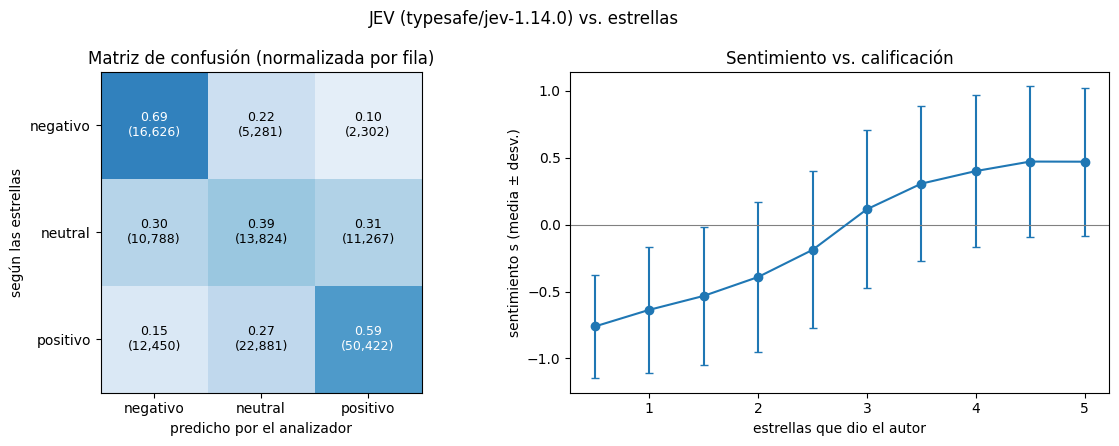

In [12]:
cache = pd.DataFrame(leer_cache().values()).drop_duplicates('id', keep='last')
salida = res[['id', 'usuario', 'item', 'grupo', 'calificacion']].merge(cache, on='id', how='inner')
salida = S.validar(salida)
cobertura = len(salida) / len(res)
print(f'Reseñas con sentimiento JEV: {len(salida):,} ({cobertura:.1%} del total)')

if EJECUTAR_TODO:
    salida.to_parquet(rutas.ANALIZADORES['jev'], index=False)
    print('Guardado:', rutas.ANALIZADORES['jev'])
else:
    salida.to_parquet(rutas.SENTIMIENTO / 'sentimiento_jev_piloto.parquet', index=False)
    print('Piloto guardado aparte (no alimenta a los experimentos 1–3).')

resumen, matriz = S.evaluar_contra_estrellas(salida)
por_grupo = {g: S.evaluar_contra_estrellas(d)[0] for g, d in salida.groupby('grupo') if len(d) > 20}
tabla = pd.DataFrame({'todas': resumen, **por_grupo})
claves = ['resenas_evaluadas', 'exactitud', 'f1_macro', 'kappa_cohen', 'f1_negativo', 'f1_neutral', 'f1_positivo',
          'spearman_s_vs_estrellas', 'mae_estrellas']
display(tabla.loc[claves])
display(matriz)
tabla.to_csv(SALIDA / 'metricas_sentimiento_jev.csv')
matriz.to_csv(SALIDA / 'matriz_confusion_jev.csv')
with open(SALIDA / 'metricas_sentimiento_jev.json', 'w') as f:
    json.dump({'modelo': JEV_MODELO, 'cobertura': cobertura, 'uso_tokens': USO, 'costo_usd': costo(USO), **resumen},
              f, indent=2, default=float, ensure_ascii=False)
S.graficar_evaluacion(salida, matriz, f'JEV ({JEV_MODELO}) vs. estrellas', SALIDA / 'evaluacion_jev.png');

## 7. Acuerdo con BETO (si ya existe su archivo)

In [13]:
if rutas.ANALIZADORES['beto'].exists():
    beto = pd.read_parquet(rutas.ANALIZADORES['beto'])
    acuerdo = S.acuerdo_entre_analizadores(beto, salida, ('beto', 'jev'))
    display(pd.Series(acuerdo).to_frame('BETO vs JEV'))
    with open(SALIDA / 'acuerdo_beto_jev.json', 'w') as f:
        json.dump(acuerdo, f, indent=2, default=float)
else:
    print('Aún no hay archivo de BETO (notebook 04).')

,BETO vs JEV
resenas_en_comun,151516
acuerdo_etiqueta,0.583635
kappa_cohen,0.352791
spearman_s,0.670326
analizadores,"[beto, jev]"


## 8. Siguiente paso

1. Descarga `datos/limpios/sentimiento/sentimiento_jev.parquet` (y `resultados/exp5/`) a tu carpeta local, en la misma ruta.
2. Vuelve a ejecutar `01`, `02` y `03`: correrán la **variante C** automáticamente.
3. Ejecuta `06_comparacion_resultados.ipynb`.

> El caché `jev_cache.jsonl` contiene solo identificadores y etiquetas, no la API key. Aun así, no subas la key a ningún repositorio.